In [69]:
import os
import squidpy as sq
import scanpy as sc
import anndata as ad
import pandas as pd
from adpbulk import ADPBulk
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

import warnings
warnings.filterwarnings("ignore")

In [70]:
out_dir = "../../results/11_compare_with_GSE294965/02_compare"
os.makedirs(out_dir, exist_ok=True)

In [71]:
adata1 = sc.read_h5ad("../../results/11_compare_with_GSE294965/01_viz_data/pseudo_bulk_adata.h5ad")
adata2 = sc.read_h5ad("../../results/02_10x_visium/02_create_bulk/adata_bulk.h5ad")

In [72]:
adata1.obs['group'].unique

<bound method Series.unique of sample
X1     Cntrl
X10    Cntrl
X11     ANCA
X12     ANCA
X13      GBM
       ...  
X62      SLE
X63     ANCA
X7       SLE
X8       SLE
X9     Cntrl
Name: group, Length: 63, dtype: category
Categories (4, object): ['ANCA', 'Cntrl', 'GBM', 'SLE']>

In [73]:
# update group annotation in Xenium data
adata1.obs['group'] = adata1.obs['group'].str.replace("SLE", "LN")
adata1.obs['group'] = adata1.obs['group'].str.replace("Cntrl", "Normal")

adata1 = adata1[adata1.obs['group'].isin(['LN', 'Normal'])]

In [74]:
adata1.X = adata1.layers['counts'].copy()
adata2.X = adata2.layers['counts'].copy()

adata1.obs['data'] = 'Xenium'
adata2.obs['data'] = 'Visium'

In [75]:
adata1

AnnData object with n_obs × n_vars = 25 × 480
    obs: 'SampleName', 'group', 'data'
    var: 'gene_ids', 'feature_types'
    uns: 'group_colors', 'log1p'
    layers: 'counts'

In [76]:
adata2

AnnData object with n_obs × n_vars = 12 × 18051
    obs: 'SampleName', 'group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'data'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'group_colors', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

In [77]:
adata = ad.concat([adata1, adata2], axis=0)

In [78]:
adata

AnnData object with n_obs × n_vars = 37 × 470
    obs: 'SampleName', 'group', 'data'
    layers: 'counts'

In [79]:
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.pca(adata, n_comps=5)

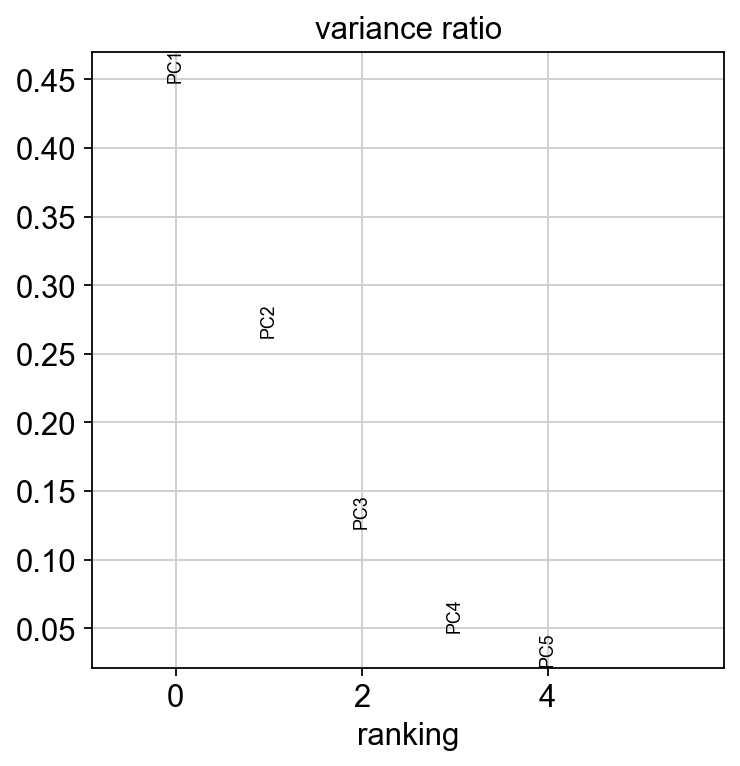

In [80]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata, n_pcs=5, log=False)

[<Axes: title={'center': 'group'}, xlabel='PC1 (44.790000915527344%)', ylabel='PC2 (26.190000534057617%)'>,
 <Axes: title={'center': 'data'}, xlabel='PC1 (44.790000915527344%)', ylabel='PC2 (26.190000534057617%)'>]

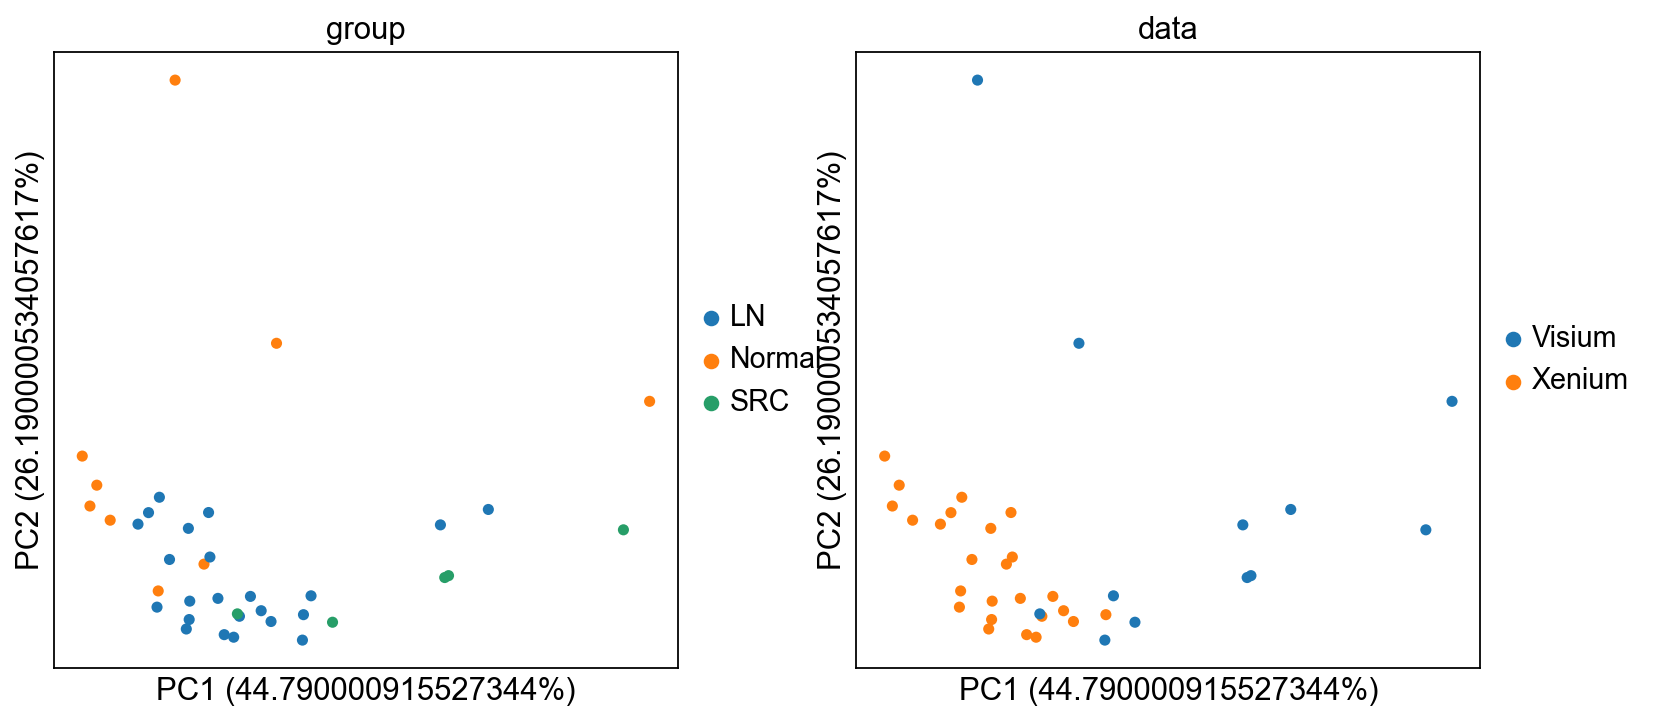

In [81]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata, 
          color=['group', 'data'],
          size=100,
          annotate_var_explained=True, 
          show=False)

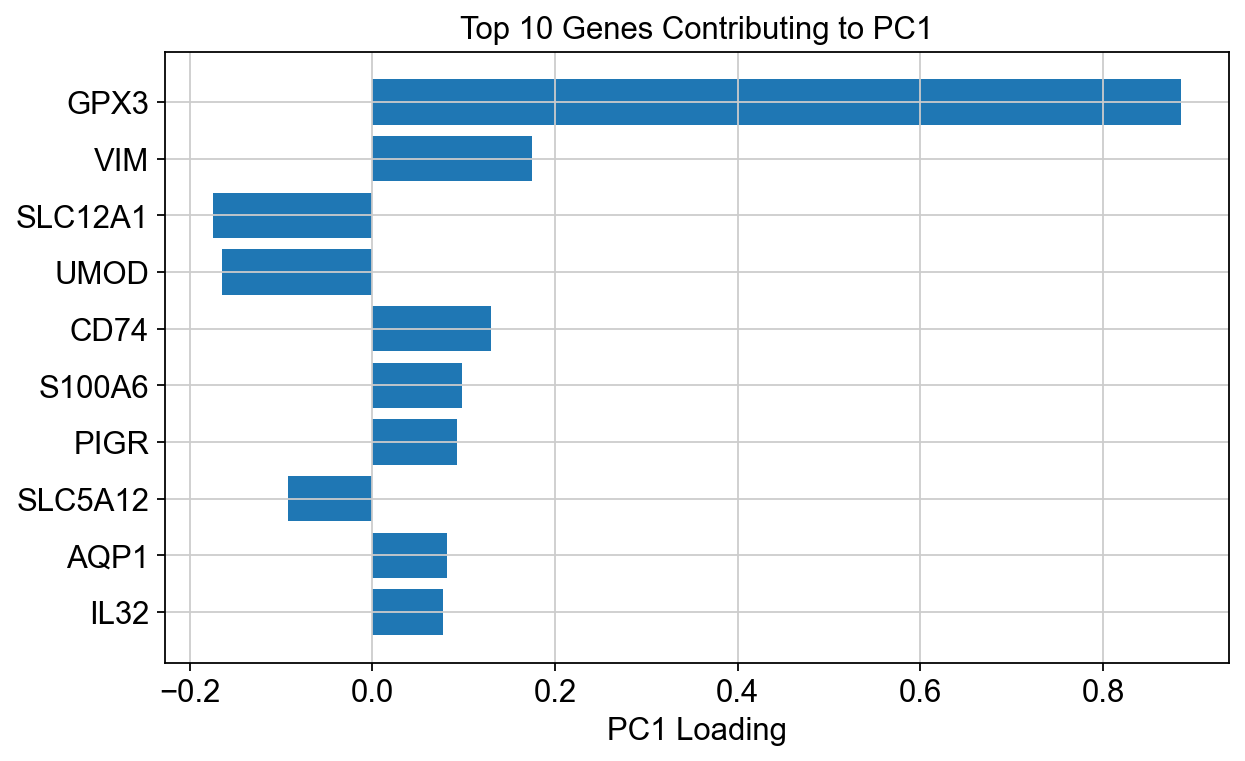

In [82]:
# Get top 10 genes for PC1
pc1 = adata.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [83]:
# perform DE analysis using DESeq2
df_counts = adata.to_df(layer="counts")
df_meta = adata.obs.copy()

df_counts.to_csv(f"{out_dir}/counts_bulk.csv")
df_meta.to_csv(f"{out_dir}/meta_bulk.csv")

adata.write_h5ad(f"{out_dir}/adata.h5ad")